# АСД: свързани зони с пукнатини в решетката
**Тема 2 – Дрон инспектор на сгради** · част по „Алгоритми и структури от данни“

| | |
|---|---|
| **Вход** | карта 0/1 с размер R × C от невронната мрежа (1 = плочка с пукнатина) |
| **Изход** | списък от зони (свързани групи плочки с 1), сортиран по площ – първо най-голямата |
| **Алгоритъм** | рекурсивно обхождане на решетката („заливане“, както при пътищата в лабиринт) + сортиране чрез сливане |
| **Сложност** | O(R·C) за обхождането, O(k log k) за сортирането на k зони |

**Защо ни трябва:** CNN казва само „тази плочка има пукнатина“. Една пукнатина обаче минава през няколко съседни плочки. За да планираме полета, трябва да знаем *колко отделни повредени зони* има, *къде е центърът* на всяка и *колко е голяма* – това е входът за частта по ЕМП (маршрут на дрона).

In [1]:
# Настройка: в Colab клонираме хранилището, локално ползваме папката src/
import os, sys
REPO_URL = "https://github.com/SimoSabev/nm-cnn-dron-inspektor.git"  # ← сменете с адреса на вашето хранилище
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    if not os.path.exists("/content/repo"):
        !git clone -q $REPO_URL /content/repo
    os.chdir("/content/repo")
elif os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())
print("Работна папка:", os.getcwd())

Работна папка: /home/user/drone-crack-inspector


In [2]:
import inspect
from IPython.display import Code, display

def show(obj):
    """Показва изходния код на функция от src/ – кодът е на едно място, тук само го четем."""
    display(Code(inspect.getsource(obj), language="python"))
import time, random
import numpy as np
import matplotlib.pyplot as plt
from src.grid_zones import (find_zones, find_zones_iterative, _fill, merge_sort, _merge,
                            sort_zones_by_area, filter_small_zones, Zone)

## 1. Идея: решетката е лабиринт
При търсене на път в лабиринт от клетка вървим рекурсивно към съседните свободни клетки и маркираме посетените, за да не се въртим в кръг. Тук правим същото, но **не търсим изход – искаме да посетим всички достижими клетки с 1**. Така „заливаме“ една зона.

```
find_zones:  за всяка клетка (r, c) по редове:
                 ако grid[r][c] == 1 и още не е посетена:
                     нова зона № k;  fill(r, c, k)

fill(r, c, k):
    ако (r, c) е извън решетката   -> край   (дъно 1)
    ако grid[r][c] == 0            -> край   (дъно 2: няма пукнатина)
    ако (r, c) вече има етикет     -> край   (дъно 3: посетена)
    етикет[r][c] = k;  добави (r, c) към зона k
    fill за 4-те (или 8-те) съседа
```

**Свързаност:** с 4 съседа (горе/долу/ляво/дясно) или с 8 (и по диагонал). Пукнатините често вървят под ъгъл и минават през плочките „по диагонал“, затова в конвейера ползваме **8-свързаност**.

In [3]:
show(_fill)
show(find_zones)

def _fill(grid, labels, r: int, c: int, zone: Zone, moves) -> None:
    """Рекурсивно "заливане" от клетка (r, c).

    Дъно на рекурсията: излизаме извън решетката, клетката е 0 (няма
    пукнатина) или вече е посетена (има етикет).
    """
    if r < 0 or r >= len(grid) or c < 0 or c >= len(grid[0]):
        return
    if grid[r][c] != 1 or labels[r][c] != 0:
        return
    labels[r][c] = zone.zone_id   # маркираме – повече няма да влезем тук
    zone.cells.append((r, c))
    for dr, dc in moves:
        _fill(grid, labels, r + dr, c + dc, zone, moves)

def find_zones(grid: Sequence[Sequence[int]], connectivity: int = 4):
    """Намира всички свързани зони от единици.

    Връща (zones, labels):
      zones  – списък от Zone в реда на откриване (по редове, отгоре надолу);
      labels – матрица R x C: 0 = няма пукнатина, k = номер на зоната (от 1).
    """
    if connectivity not in (4, 8):
        raise ValueError("connectivity трябва да е 4 или 8")
    moves = MOVES_4 if connectivity == 4 else MOVES_8
    rows, cols = _validate(grid)
    labels = [[0] * cols for _ in range(rows)]
    zones: List[Zone] = []

    # Дълбочината на рекурсията може да стигне R·C (зона-"змия").
    needed = rows * cols + 1000
    old_limit = sys.getrecursionlimit()
    if needed > old_limit:
        sys.setrecursionlimit(needed)
    try:
        for r in range(rows):
            for c in range(cols):
                if grid[r][c] == 1 and labels[r][c] == 0:
                    zone = Zone(zone_id=len(zones) + 1)
                    _fill(grid, labels, r, c, zone, moves)
                    zones.append(zone)
    finally:
        sys.setrecursionlimit(old_limit)
    return zones, labels

## 2. Пример стъпка по стъпка

In [4]:
grid = [[1, 1, 0, 0, 1, 0],
        [0, 1, 0, 0, 1, 0],
        [0, 0, 0, 1, 1, 0],
        [1, 0, 0, 0, 0, 0],
        [1, 1, 0, 0, 1, 1]]

for conn in (4, 8):
    zones, labels = find_zones(grid, connectivity=conn)
    print(f"{conn}-свързаност: {len(zones)} зони")
    for row in labels:
        print("   ", " ".join(str(x) if x else "." for x in row))
    for z in zones:
        print(f"    зона {z.zone_id}: площ {z.area}, клетки {z.cells}, център {z.center}")
    print()

4-свързаност: 4 зони
    1 1 . . 2 .
    . 1 . . 2 .
    . . . 2 2 .
    3 . . . . .
    3 3 . . 4 4
    зона 1: площ 3, клетки [(0, 0), (0, 1), (1, 1)], център (0.8333333333333333, 1.1666666666666665)
    зона 2: площ 4, клетки [(0, 4), (1, 4), (2, 4), (2, 3)], център (1.75, 4.25)
    зона 3: площ 3, клетки [(3, 0), (4, 0), (4, 1)], център (4.166666666666666, 0.8333333333333333)
    зона 4: площ 2, клетки [(4, 4), (4, 5)], център (4.5, 5.0)

8-свързаност: 4 зони
    1 1 . . 2 .
    . 1 . . 2 .
    . . . 2 2 .
    3 . . . . .
    3 3 . . 4 4
    зона 1: площ 3, клетки [(0, 0), (0, 1), (1, 1)], център (0.8333333333333333, 1.1666666666666665)
    зона 2: площ 4, клетки [(0, 4), (1, 4), (2, 4), (2, 3)], център (1.75, 4.25)
    зона 3: площ 3, клетки [(3, 0), (4, 0), (4, 1)], център (4.166666666666666, 0.8333333333333333)
    зона 4: площ 2, клетки [(4, 4), (4, 5)], център (4.5, 5.0)



При 4-свързаност зоната в горния десен ъгъл (клетки (0,4), (1,4), (2,4), (2,3)) е една, а двете клетки долу вдясно – друга. При 8-свързаност резултатът тук е същият, защото няма диагонални връзки между зоните – виж следващия пример.

In [5]:
diag = [[1, 0, 0],
        [0, 1, 0],
        [0, 0, 1]]
print("4-свързаност:", len(find_zones(diag, 4)[0]), "зони")
print("8-свързаност:", len(find_zones(diag, 8)[0]), "зона  <- една диагонална пукнатина")

4-свързаност: 3 зони
8-свързаност: 1 зона  <- една диагонална пукнатина


## 3. Сортиране на зоните по площ – сортиране чрез сливане
Инженерът иска първо най-голямата повреда. Сортираме с **merge sort** (рекурсивен, разделяй и владей):

1. Разделяме списъка на две половини.
2. Сортираме всяка половина рекурсивно (дъно: 0 или 1 елемент).
3. Сливаме двете сортирани половини с два указателя.

$T(n) = 2T(n/2) + O(n) \Rightarrow T(n) = O(n \log n)$ във **всеки** случай (за разлика от бързото сортиране, което в най-лошия случай е O(n²)). Сортирането е **стабилно** – при равна площ запазва реда; ключът е (−площ, горен ред, лява колона), за да е редът еднозначен.

In [6]:
show(merge_sort)
show(_merge)
show(sort_zones_by_area)

def merge_sort(items: List, key: Callable = lambda x: x) -> List:
    """Рекурсивно сортиране чрез сливане (нарастващо по key). Стабилно.

    T(n) = 2·T(n/2) + O(n)  =>  T(n) = O(n log n).
    """
    if len(items) <= 1:            # дъно: 0 или 1 елемент е вече сортиран
        return list(items)
    mid = len(items) // 2
    left = merge_sort(items[:mid], key)
    right = merge_sort(items[mid:], key)
    return _merge(left, right, key)

def _merge(left: List, right: List, key: Callable) -> List:
    result = []
    i = j = 0
    while i < len(left) and j < len(right):
        # "<=" запазва реда на равните елементи -> стабилност
        if key(left[i]) <= key(right[j]):
            result.append(left[i])
            i += 1
        else:
            result.append(right[j])
            j += 1
    result.extend(left[i:])
    result.extend(right[j:])
    return result

def sort_zones_by_area(zones: List[Zone]) -> List[Zone]:
    """Зоните по площ – първо най-голямата.

    При равна площ: по-горната, после по-лявата (детерминиран ред).
    Ключът е (-площ, ред_мин, кол_мин), за да ползваме нарастващо сортиране.
    """
    return merge_sort(zones, key=lambda z: (-z.area, z.bbox[0], z.bbox[1]))

In [7]:
zones, labels = find_zones(grid, connectivity=8)
for z in sort_zones_by_area(zones):
    print(f"зона {z.zone_id}: площ {z.area}, обхват {z.bbox}")

зона 2: площ 4, обхват (0, 3, 2, 4)
зона 1: площ 3, обхват (0, 0, 1, 1)
зона 3: площ 3, обхват (3, 0, 4, 1)
зона 4: площ 2, обхват (4, 4, 4, 5)


## 4. Сложност

**Обхождане.** Всяка клетка получава етикет **само веднъж** (след това дъно 3 я спира). Всяка клетка се „пита“ от най-много 4 (или 8) съседа. Значи броят извиквания на `fill` е ≤ 1 + 8·R·C → **O(R·C)** време.
Памет: матрицата с етикети O(R·C) + стекът на рекурсията. В най-лошия случай (цялата решетка е една зона-„змия“) дълбочината е R·C → **O(R·C)** памет. Затова `find_zones` временно вдига `sys.setrecursionlimit`. За много големи решетки има и итеративен вариант с явен стек (`find_zones_iterative`) – използваме го само за проверка.

**Сортиране.** O(k log k) за k зони; k ≤ R·C, но на практика k е малко.

**Общо:** O(R·C + k log k). Проверяваме емпирично: времето трябва да расте линейно с броя клетки.

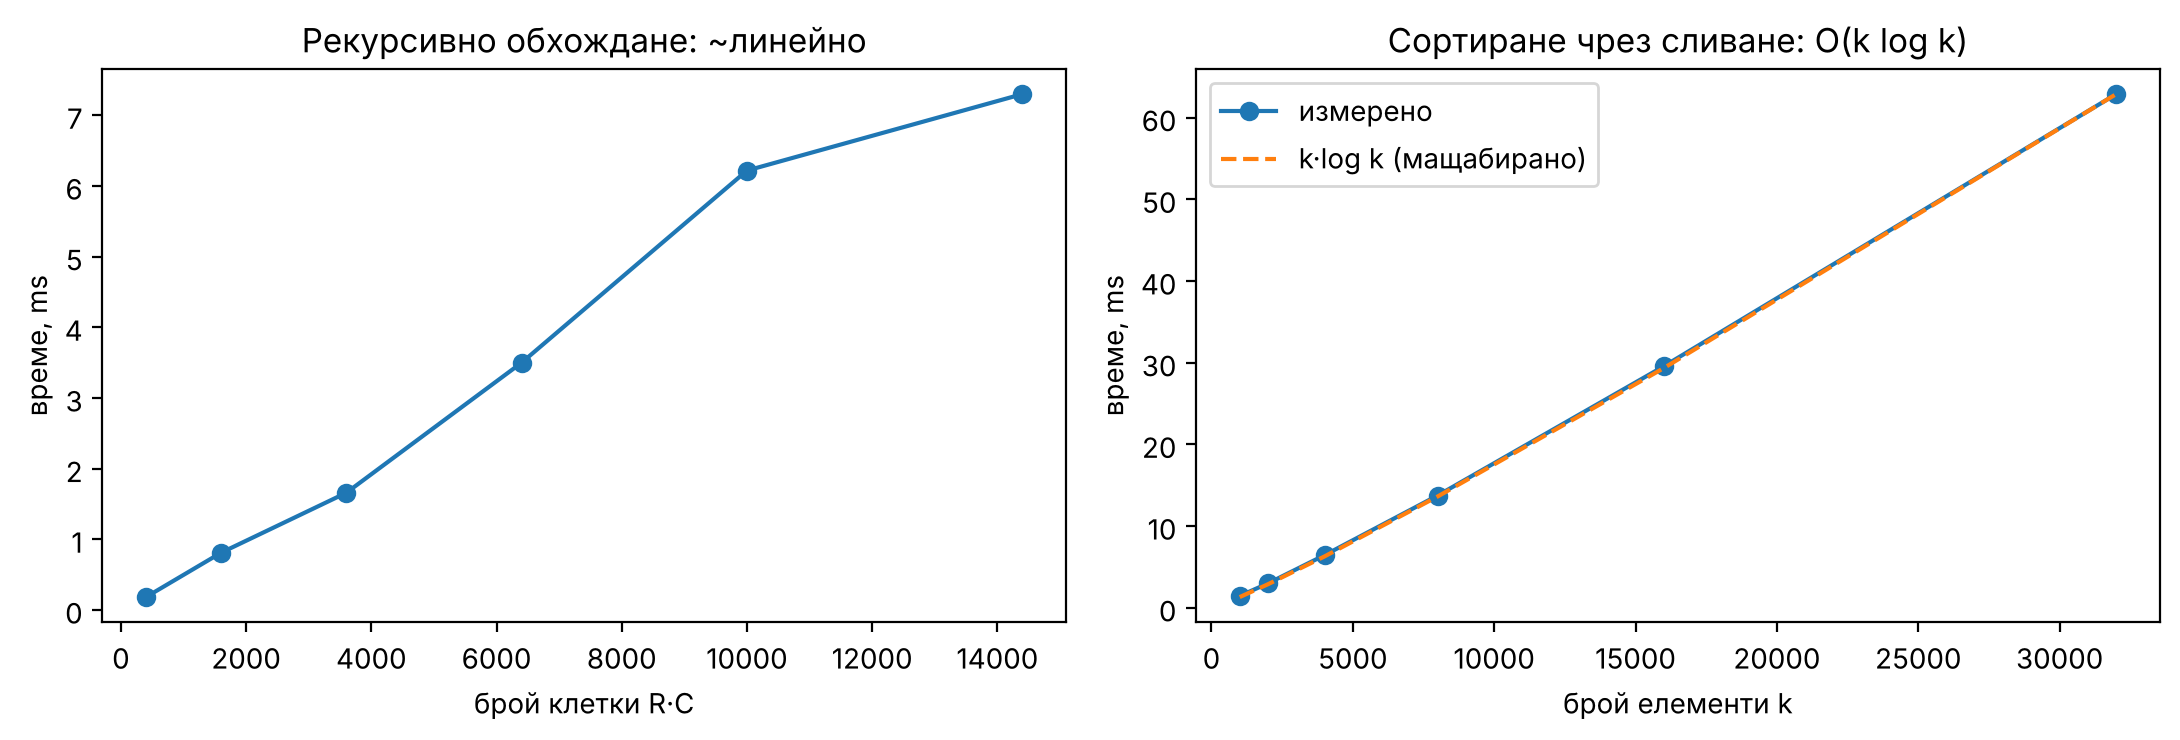

R·C =    400:    0.18 ms   (0.45 µs на клетка)
R·C =   1600:    0.81 ms   (0.51 µs на клетка)
R·C =   3600:    1.66 ms   (0.46 µs на клетка)
R·C =   6400:    3.50 ms   (0.55 µs на клетка)
R·C =  10000:    6.22 ms   (0.62 µs на клетка)
R·C =  14400:    7.30 ms   (0.51 µs на клетка)


In [8]:
sizes, t_rec = [], []
rng = random.Random(0)
for n in [20, 40, 60, 80, 100, 120]:
    g = [[int(rng.random() < 0.35) for _ in range(n)] for _ in range(n)]
    t0 = time.perf_counter()
    for _ in range(3):
        find_zones(g, 8)
    t_rec.append((time.perf_counter() - t0) / 3 * 1000)
    sizes.append(n * n)

ks, t_ms = [], []
for k in [1000, 2000, 4000, 8000, 16000, 32000]:
    data = [rng.random() for _ in range(k)]
    t0 = time.perf_counter(); merge_sort(data); t_ms.append((time.perf_counter() - t0) * 1000); ks.append(k)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(sizes, t_rec, "o-"); ax[0].set_xlabel("брой клетки R·C"); ax[0].set_ylabel("време, ms")
ax[0].set_title("Рекурсивно обхождане: ~линейно")
klogk = np.array(ks) * np.log2(ks)
ax[1].plot(ks, t_ms, "o-", label="измерено")
ax[1].plot(ks, klogk / klogk[-1] * t_ms[-1], "--", label="k·log k (мащабирано)")
ax[1].set_xlabel("брой елементи k"); ax[1].set_ylabel("време, ms"); ax[1].legend()
ax[1].set_title("Сортиране чрез сливане: O(k log k)")
plt.tight_layout(); plt.savefig("results/asd_complexity.png", dpi=120); plt.show()
for s, t in zip(sizes, t_rec):
    print(f"R·C = {s:>6}: {t:7.2f} ms   ({t / s * 1e3:.2f} µs на клетка)")

Времето на клетка остава почти постоянно → линейна зависимост, както очаквахме.

## 5. Тестове
Пълните тестове са в `tests/test_grid_zones.py` (празна решетка, една зона, 4 срещу 8 съседа, познат пример, всяка 1 е в точно една зона, рекурсивният и итеративният вариант дават еднакъв резултат на случайни решетки, дълбока рекурсия, грешен вход, merge sort срещу `sorted`, стабилност).

In [9]:
!python -m pytest -q --color=no -p no:cacheprovider tests/test_grid_zones.py

...................

.............................                         [100%]
48 passed in 0.05s


In [10]:
# Няколко проверки и тук, за да се видят директно
assert find_zones([])[0] == []
assert len(find_zones([[1, 1], [1, 1]])[0]) == 1
assert len(find_zones(diag, 4)[0]) == 3 and len(find_zones(diag, 8)[0]) == 1
rng = random.Random(42)
for _ in range(50):
    g = [[int(rng.random() < 0.4) for _ in range(15)] for _ in range(12)]
    a, la = find_zones(g, 8); b, lb = find_zones_iterative(g, 8)
    assert la == lb and sum(z.area for z in a) == sum(map(sum, g))
data = [rng.randint(0, 100) for _ in range(500)]
assert merge_sort(data) == sorted(data)
print("Всички проверки минаха ✔")

Всички проверки минаха ✔


## 6. На реална по размер карта (20 × 30 плочки)

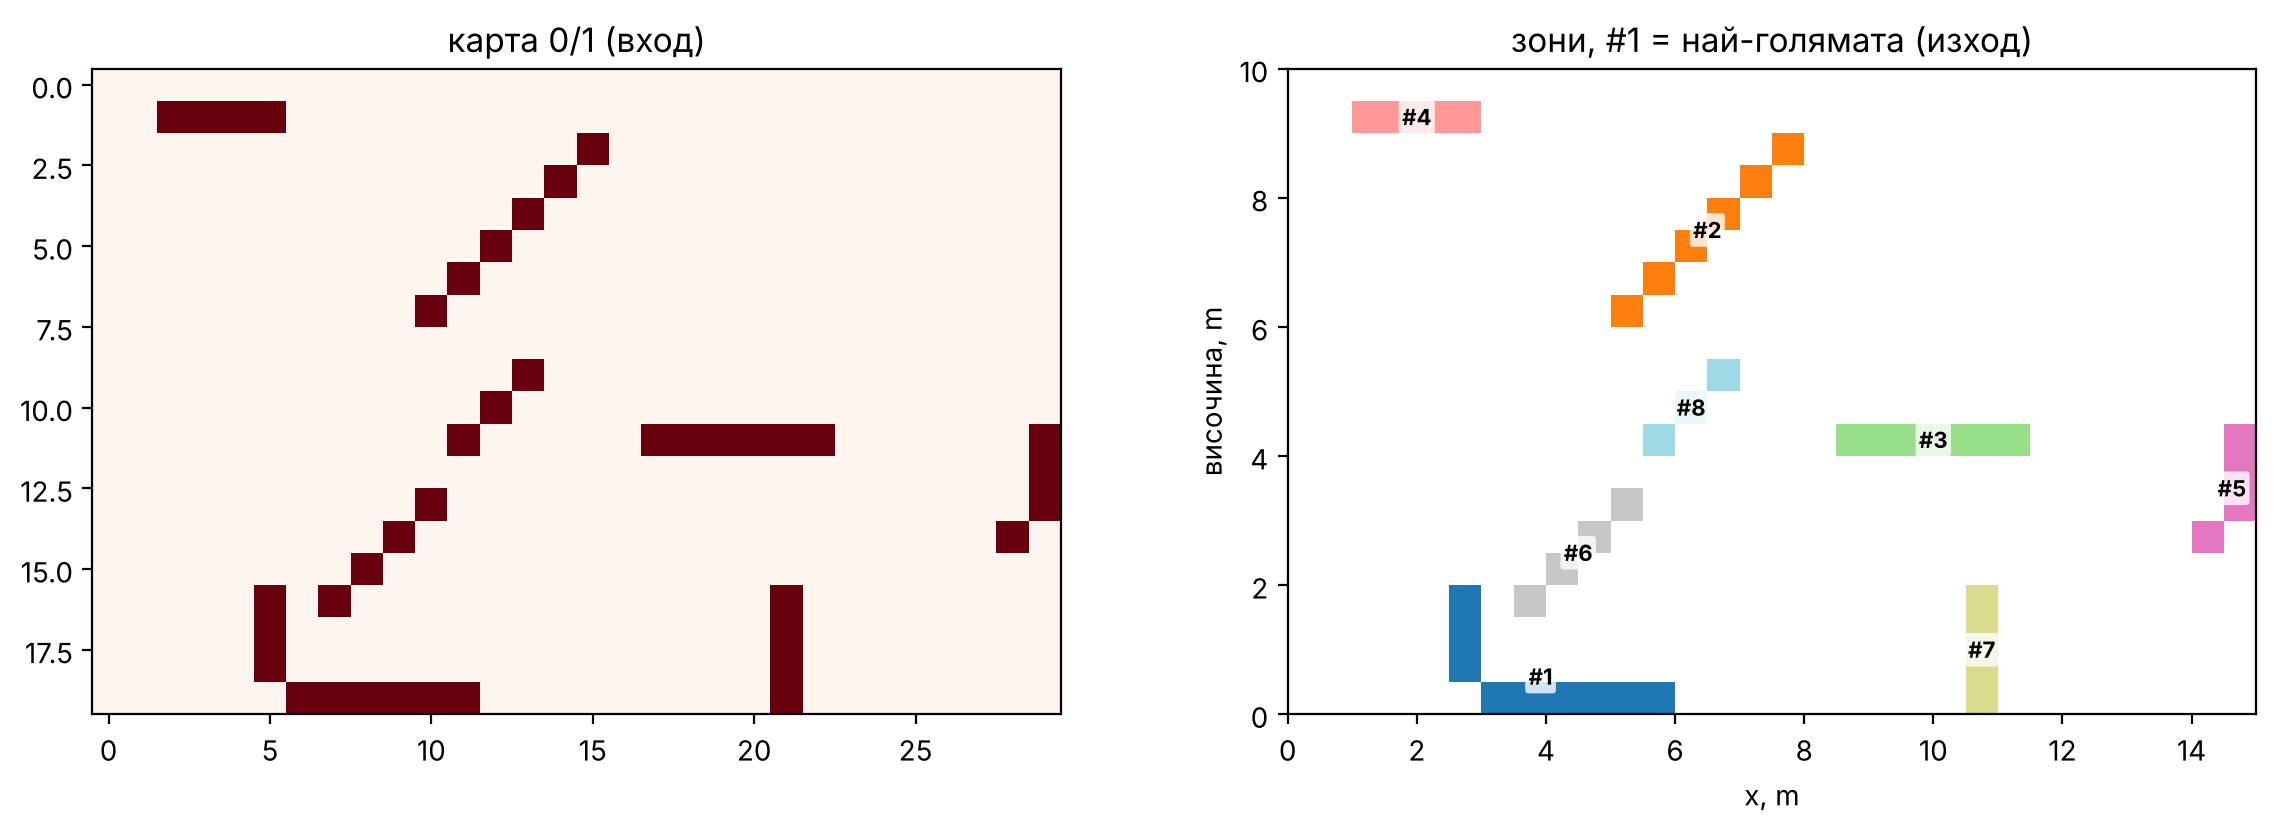

#1: площ  9 плочки, център (ред, кол) = (18.8, 7.8)
#2: площ  6 плочки, център (ред, кол) = (5.0, 13.0)
#3: площ  6 плочки, център (ред, кол) = (11.5, 20.0)
#4: площ  4 плочки, център (ред, кол) = (1.5, 4.0)
#5: площ  4 плочки, център (ред, кол) = (13.0, 29.2)
#6: площ  4 плочки, център (ред, кол) = (15.0, 9.0)
#7: площ  4 плочки, център (ред, кол) = (18.0, 21.5)
#8: площ  3 плочки, център (ред, кол) = (10.5, 12.5)


In [11]:
from src.tiling import random_crack_mask
from src.viz import plot_zones

crack_map = random_crack_mask(20, 30, n_cracks=9, max_len=7, seed=2)  # вместо изхода на CNN
zones, labels = find_zones(crack_map.tolist(), connectivity=8)
zones = sort_zones_by_area(zones)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].imshow(crack_map, cmap="Reds"); ax[0].set_title("карта 0/1 (вход)")
plot_zones(np.array(labels), zones, ax[1], tile_m=0.5, title="зони, #1 = най-голямата (изход)")
plt.tight_layout(); plt.show()
for i, z in enumerate(zones, 1):
    print(f"#{i}: площ {z.area:>2} плочки, център (ред, кол) = ({z.center[0]:.1f}, {z.center[1]:.1f})")

## 7. Изводи и връзка с конвейера
* Рекурсивното обхождане намира всички зони за **O(R·C)** – за стена 20 × 30 плочки това са части от милисекундата.
* Центровете и площите на зоните са входът за ЕМП: центърът → точка, която дронът трябва да посети; площта → колко енергия струва огледът.
* **Ограничение:** рекурсията в Python има лимит на дълбочината – решаваме го с `sys.setrecursionlimit` (зоните са малки) или с итеративен вариант.
* **Пълнотата е най-важна:** не изхвърляме малките зони (`min_area = 1`) – единична плочка може да е началото на пукнатина.